# Etapa 08: Datos reales

Las etapas 01 a 07 las hicimos sobre una base simulada porque la exportación del laboratorio no estaba lista. Al
final del semestre Daniel Arias Mutis, que trabaja en el laboratorio, consiguió la exportación real (con los clientes
anonimizados) y nos propuso dos cosas: Clasificar a los clientes por su volumen semanal o mensual y a los lotes por
su tamaño. Además nos dijo que las llegadas de muestras le sonaban a un proceso de Poisson. Esta etapa cuenta qué
pasó cuando pusimos a prueba esa idea.

Dos reglas de entrada. La primera es que solo usamos fechas de desarrollo: Todo lo que ingresó desde el corte de
prueba (es decir 2026) se queda por fuera de cada cuenta. Así no gastamos un periodo que nadie ha mirado y además es
donde la base empieza a cambiar de comportamiento. La segunda es que el archivo es confidencial y no viaja con el
proyecto así que si no está (por ejemplo en Colab) cada sección muestra una nota en vez de cifras.

← Anterior: [Etapa 07: Evaluación final](07_evaluacion_final.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)

## Código del proyecto

La celda siguiente vuelve a crear el paquete `proyecto/` dentro de la sesión. Así el notebook funciona en Google Colab sin clonar ningún repositorio: Basta con ejecutarla una vez (*Entorno de ejecución → Ejecutar todas*). En una copia local del repositorio no reemplaza ningún archivo y la sección se puede plegar desde su título. Trae también los guiones de las etapas anteriores: Si sus resultados no están en la sesión, la etapa los vuelve a calcular en silencio antes de empezar.

In [ ]:
# Código del proyecto. Esta celda recrea en el directorio de trabajo:
#   - el paquete `proyecto/` (55 módulos) y `configuracion/mapeo_columnas.json`;
#   - los guiones de las 7 etapas previas (se reconstruyen si faltan);
# para que el notebook funcione en Google Colab sin clonar el repositorio. Todo viaja
# al final de la celda como un .tar.xz en base64 (73 archivos, 219 kB).
# Antes de extraer se comprueba su huella SHA-256. Un archivo que ya existe con el
# mismo contenido no se toca, y uno que existe con otro contenido (una copia local
# del repositorio con cambios, por ejemplo) se conserva y se avisa; para
# reemplazarlo hay que poner SOBRESCRIBIR = True.
import base64
import hashlib
import importlib
import io
import os
import sys
import tarfile
from pathlib import Path

SOBRESCRIBIR = False


def recrear_proyecto(huella, codificado):
    datos = base64.b64decode(codificado)
    if hashlib.sha256(datos).hexdigest() != huella:
        raise ValueError("El código embebido está dañado: su SHA-256 no coincide.")
    escritos, iguales, conservados = 0, 0, []
    with tarfile.open(fileobj=io.BytesIO(datos), mode="r:xz") as archivo:
        for miembro in archivo.getmembers():
            nombre = miembro.name
            if Path(nombre).is_absolute() or ".." in Path(nombre).parts:
                raise ValueError(f"Ruta no permitida en el archivo: {nombre}")
            contenido, destino = archivo.extractfile(miembro).read(), Path(nombre)
            if destino.exists() and destino.read_bytes() == contenido:
                iguales += 1
            elif destino.exists() and not SOBRESCRIBIR:
                conservados.append(nombre)
            else:
                destino.parent.mkdir(parents=True, exist_ok=True)
                destino.write_bytes(contenido)
                escritos += 1
    if os.getcwd() not in sys.path:
        sys.path.insert(0, os.getcwd())
    importlib.invalidate_caches()
    print(f"Código del proyecto: {escritos} archivos escritos, {iguales} ya estaban iguales.")
    if conservados:
        print(f"Se conservaron {len(conservados)} archivos locales distintos:", ", ".join(conservados))


recrear_proyecto(
    huella="d271f52007f7824be0deb459673b4be9a152c1b6ae2d8c2081ca2f0fd9b4cdbf",
    codificado="...",
)

## Desarrollo de la etapa

In [1]:
from proyecto.base.artefactos import iniciar_etapa
from proyecto.base.salida import mostrar
from proyecto.etapas import datos_reales

iniciar_etapa("08_datos_reales")
c = datos_reales.iniciar()
mostrar(c.encabezado)

## 1. La base real

La exportación no viene con una fila por muestra. Trae una fila por cada muestra, especificación y lectura así que
una muestra con seis especificaciones y un reanálisis ocupa siete u ocho filas. Lo primero que hicimos fue volver a
una fila por muestra y después agrupar las muestras en **lotes**. Un lote son las muestras que un mismo cliente
ingresa el mismo día y del mismo tipo: **Producto** (producto terminado, materia prima, agua, granel o envase) o
**planta** (superficies, ambientes y personal que el laboratorio recoge en un muestreo en la planta del cliente).

In [2]:
datos_reales.la_base(c).mostrar()

Partición,Desde,Hasta,Muestras,Lotes,Clientes,Muestreo en planta,No conformidad
Entrenamiento,2024-06-04,2025-06-27,15710,1707,70,0.676,0.036
Validación,2025-07-01,2025-12-19,5839,836,57,0.622,0.041


## 2. Llegadas: Muestras o lotes

### 2.1 La idea de Poisson

Un conteo de Poisson describe cuántos eventos caen en un intervalo cuando llegan sueltos, sin ponerse de acuerdo y
con una tasa ${\color{#3B64A8}{\lambda}}$ estable. La probabilidad de ver $k$ llegadas en una semana es

$$P(N = k) = \frac{e^{-{\color{#3B64A8}{\lambda}}}\,{\color{#3B64A8}{\lambda}}^{k}}{k!}$$

y tiene una propiedad que se puede revisar con los datos: Su varianza es igual a su media. Por eso usamos el
**índice de dispersión**, la varianza sobre la media de los conteos semanales de cada cliente. Si vale cerca de 1
los conteos se parecen a una Poisson, si es mucho mayor hay **sobredispersión** (semanas vacías mezcladas con semanas
llenas) y si es menor los envíos son más regulares de lo que daría el azar:

$$I = \frac{{\color{#B8423F}{s^2}}}{{\color{#2F8A4E}{\bar x}}}, \qquad
D = \sum_{t=1}^{n} \frac{(x_t - {\color{#2F8A4E}{\bar x}})^2}{{\color{#2F8A4E}{\bar x}}} \sim \chi^2_{n-1}$$

El estadístico $D$ es la prueba de dispersión: Si los conteos son Poisson se distribuye como una ji cuadrado con
$n - 1$ grados de libertad (una por semana menos una) y de ahí sale un valor p para cada cola.

Esperábamos que las muestras por semana de cada cliente pasaran la prueba. No pasó así. Antes de descartar la idea
de Daniel nos dimos cuenta de que el laboratorio no recibe muestras sueltas sino lotes (una caja con varias muestras
o una visita de muestreo) así que repetimos la cuenta con los lotes. Para cada tipo usamos los clientes con
suficientes lotes y las semanas entre su primer y su último envío, para que un cliente que llegó tarde no sume ceros
que no son suyos. La línea de cada figura es lo que se esperaría si cada cliente fuera una Poisson con su propia tasa.

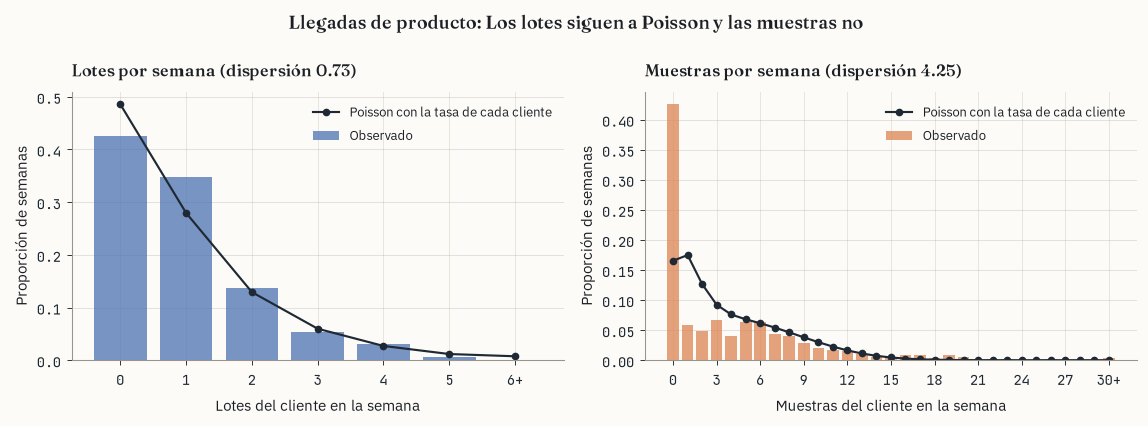

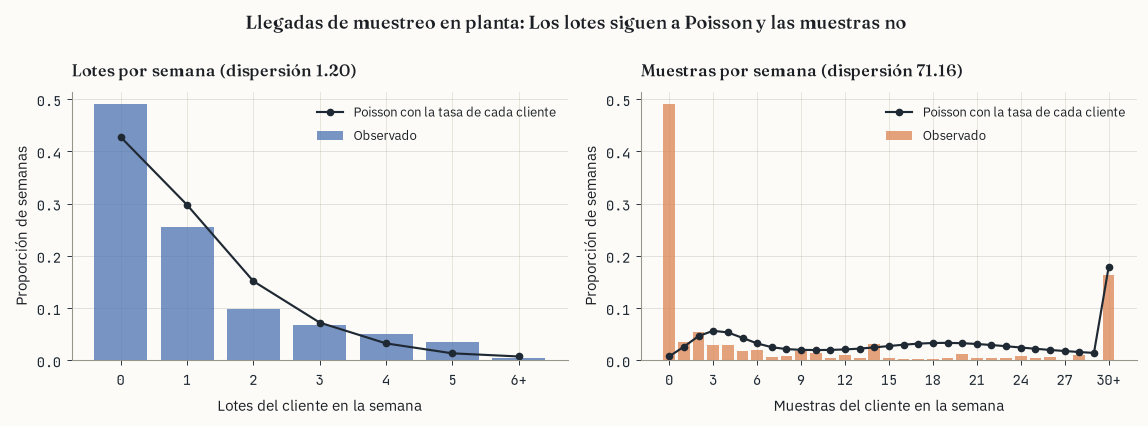

Tipo,Clientes,Índice muestras (mediana),Índice muestras (máximo),Índice lotes (mediana),Muestras sobredispersas,Lotes sobredispersos,Lotes subdispersos,Índice compuesto predicho (mediana)
producto,22,4.25,14.58,0.73,0.95,0.05,0.50,6.00
muestreo en planta,8,71.16,396.43,1.20,1.00,0.25,0.00,59.98


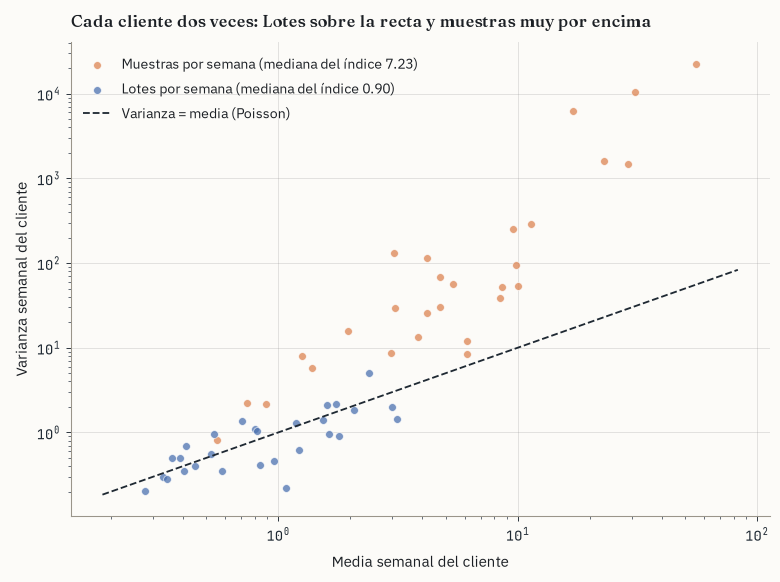

In [3]:
datos_reales.llegadas(c).mostrar()

### 2.2 Por qué las muestras no son Poisson aunque los lotes sí

Si llegan $N$ lotes en la semana y el lote $i$ trae $X_i$ muestras, el total de muestras es una **Poisson
compuesta**:

$$S = \sum_{i=1}^{{\color{#3B64A8}{N}}} {\color{#C46A2B}{X_i}}, \qquad {\color{#3B64A8}{N}} \sim
\mathrm{Poisson}({\color{#3B64A8}{\lambda}})$$

$$E[S] = {\color{#3B64A8}{\lambda}}\, E[{\color{#C46A2B}{X}}], \qquad
\mathrm{Var}[S] = {\color{#3B64A8}{\lambda}}\, E[{\color{#C46A2B}{X}}^2], \qquad
\frac{\mathrm{Var}[S]}{E[S]} = \frac{E[{\color{#C46A2B}{X}}^2]}{E[{\color{#C46A2B}{X}}]}$$

O sea que aunque los lotes sean Poisson el índice de las muestras ya no es 1 sino el cociente entre el segundo
momento y la media del tamaño de lote. Si todos los lotes trajeran una muestra volveríamos a la Poisson y entre más
varíe el tamaño más grande es el índice. Esa es la cuenta que aparece en la segunda nota de arriba y explica por qué
los clientes de planta (con lotes de tamaño muy variable) tienen índices de muestras tan altos.

## 3. Tamaño de los lotes

Si los lotes llegan como Poisson lo que queda por describir es cuántas muestras trae cada uno. Como un lote tiene al
menos una muestra modelamos el tamaño como uno más un conteo y probamos tres opciones: Uno más una Poisson (lo que
hace nuestra simulación), uno más una geométrica (cada muestra adicional llega con la misma probabilidad que la
anterior) y uno más una binomial negativa, que agrega un parámetro $r$ para colas más largas (con $r = 1$ es la
geométrica). Las comparamos con el AIC, que premia el ajuste y castiga cada parámetro adicional (gana el menor).

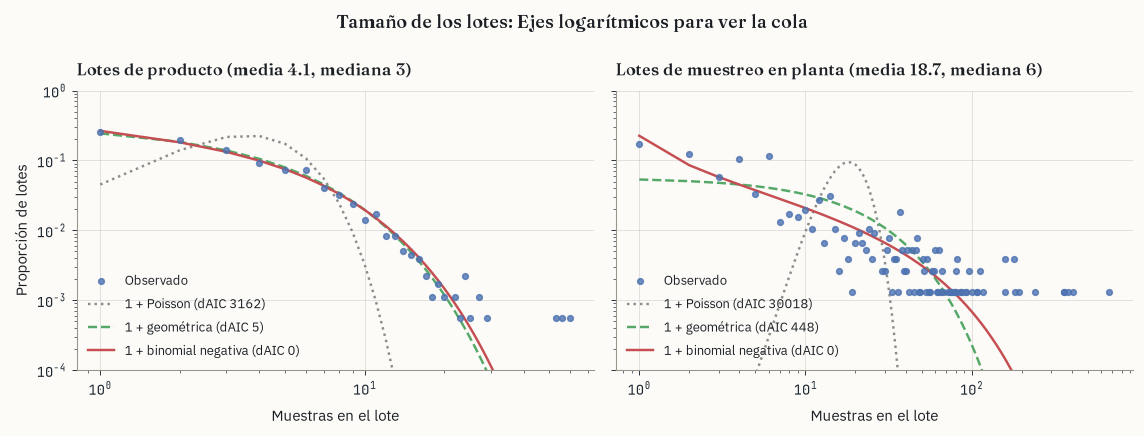

Tipo,Modelo,Parámetros,Media de X menos uno,r,AIC,Diferencia de AIC
producto,1 + Poisson,1,3.10,∞,11266.76,3161.53
producto,1 + geométrica,1,3.10,1.00,8110.64,5.40
producto,1 + binomial negativa,2,3.10,0.88,8105.23,0.00
muestreo en planta,1 + Poisson,1,17.71,∞,35518.93,30018.39
muestreo en planta,1 + geométrica,1,17.71,1.00,5948.19,447.66
muestreo en planta,1 + binomial negativa,2,17.71,0.39,5500.53,0.00


Tipo,Muestras en el lote,Observada,1 + Poisson,1 + geométrica,1 + binomial negativa
producto,1,0.255,0.045,0.244,0.265
producto,2,0.194,0.140,0.185,0.182
producto,3 a 4,0.233,0.441,0.245,0.232
producto,5 a 9,0.242,0.370,0.246,0.235
producto,10 a 19,0.067,0.005,0.076,0.079
producto,20 a 49,0.007,0.000,0.005,0.007
producto,50 o más,0.002,0.000,0.000,0.000
muestreo en planta,1,0.169,0.000,0.053,0.225
muestreo en planta,2,0.122,0.000,0.051,0.086
muestreo en planta,3 a 4,0.163,0.000,0.093,0.103


In [4]:
datos_reales.lotes(c).mostrar()

## 4. Segmentos de clientes

La otra propuesta de Daniel era clasificar a los clientes por su volumen. Usamos el mismo procedimiento de la etapa 06
(K-means con la regla de la silueta y nombres que salen de las variables en que cada grupo más se aparta) pero ahora
con variables que salen de las secciones anteriores: Muestras y lotes por semana, dispersión semanal, proporción de
semanas con envío, tamaño de lote, proporción de muestreo en planta y no conformidad.

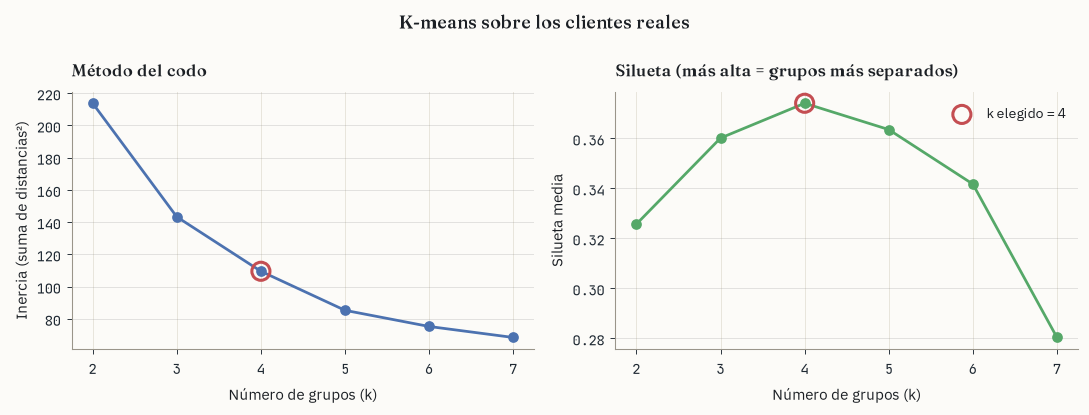

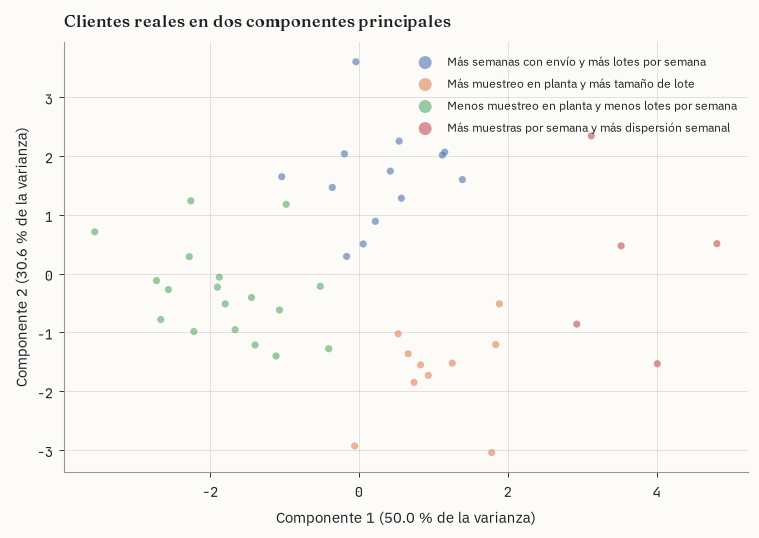

Segmento,Clientes,Proporción de clientes,Proporción de muestras,No conformidad,Variables que lo distinguen
Más semanas con envío y más lotes por semana,13,0.283,0.279,0.028,"semanas con envío +1.1 DE, lotes por semana +0.8 DE"
Más muestreo en planta y más tamaño de lote,10,0.217,0.099,0.037,"muestreo en planta +1.2 DE, tamaño de lote +0.8 DE, semanas con envío -0.8 DE, lotes por semana -0.6 DE"
Menos muestreo en planta y menos lotes por semana,18,0.391,0.060,0.115,"muestreo en planta -0.8 DE, lotes por semana -0.6 DE, semanas con envío -0.6 DE, no conformidad +0.6 DE, muestras por semana -0.6 DE, tamaño de lote -0.5 DE"
Más muestras por semana y más dispersión semanal,5,0.109,0.563,0.032,"muestras por semana +2.4 DE, dispersión semanal +2.3 DE, tamaño de lote +1.5 DE, muestreo en planta +1.2 DE, lotes por semana +1.2 DE, semanas con envío +0.7 DE"


Segmento,muestras por semana,dispersión semanal,semanas con envío,lotes por semana,tamaño de lote,muestreo en planta,no conformidad
Más semanas con envío y más lotes por semana,6.15,6.03,0.81,1.22,5.29,0.15,0.03
Más muestreo en planta y más tamaño de lote,4.40,24.67,0.27,0.39,12.35,0.98,0.02
Menos muestreo en planta y menos lotes por semana,0.96,4.45,0.28,0.30,3.42,0.00,0.11
Más muestras por semana y más dispersión semanal,28.93,344.56,0.68,1.74,23.11,0.99,0.01


In [5]:
datos_reales.segmentos(c).mostrar()

## 5. Riesgo de no conformidad al ingreso

Para no quedarnos solo en la descripción probamos rápido si la base real deja anticipar qué muestras van a salir no
conformes con lo que se sabe al recibirlas: Sector, origen de la muestra, forma farmacéutica, si el cuadro analítico
es complejo, número de especificaciones, tipo y tamaño del lote y la historia del cliente. La historia solo cuenta los
dictámenes que ya se conocían el día del ingreso para que el modelo no vea el futuro. Ajustamos en entrenamiento y
medimos en validación con el ROC-AUC (qué tan bien ordena el riesgo) y la precisión media (qué tan limpia sale la
lista de alertas cuando la clase positiva es rara).

In [6]:
datos_reales.riesgo(c).mostrar()

Modelo,ROC-AUC,Precisión media
Línea base (tasa de entrenamiento),0.500,0.041
Solo la historia del cliente,0.673,0.105
Regresión logística,0.678,0.103
Árbol de decisión,0.692,0.072


## 6. Qué tan lejos estaba la simulación

Le dimos varias vueltas a si valía la pena rehacer las etapas anteriores con este hallazgo. Antes de decidir
comparamos pieza por pieza el mecanismo de llegada de la simulación con lo que encontramos en la base real.

In [7]:
datos_reales.comparacion_simulacion(c).mostrar()

Pieza,Simulación,Exportación real
Número de lotes,Poisson por cliente y día con tasa que cambia por semana; los clientes industriales con un número casi fijo por semana,Cerca de Poisson: Índice semanal 0.73 (producto) y 1.20 (planta)
Tamaño del lote,1 + Poisson con tamaño medio de 1.8 a 3.0 según el segmento,"1 + binomial negativa: Media 4.1 (producto) y 18.7 (planta), máximo 675"
Tipos de lote,Uno solo,Producto y planta (66.2 % de las muestras en planta)
Índice de las muestras,E[X²]/E[X] de 2.2 a 3.7,"Mediana 7.23, máximo 407"


## 7. Cierre

In [8]:
datos_reales.cierre(c).mostrar()

← Anterior: [Etapa 07: Evaluación final](07_evaluacion_final.ipynb)<br>[Notebook completo](Proyecto_Final.ipynb)